In [1]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import itertools

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# إصلاح توافقية np.bool مع NumPy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

import albumentations as A

# ================================================================
# 1. Parameter Settings
# ================================================================
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
EPOCHS = 30

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

# Set random seed for reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ================================================================
# 2. Load Metadata and Image Paths
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None: 
        continue
    if fname in image_files_1:
        full = os.path.join(DATASET_PATH_1, fname)
    else:
        full = os.path.join(DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path', 'label'])
print("Total images found:", len(df))

# Encode string labels to integers
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# 3. Stratified Dataset Split (70% Train / 15% Val / 15% Test)
# ================================================================
train_and_val, test_df = train_test_split(
    df, test_size=TEST_RATIO, stratify=df['label_enc'], random_state=RANDOM_STATE
)
relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_and_val, test_size=relative_val_ratio, stratify=train_and_val['label_enc'], random_state=RANDOM_STATE
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

# ================================================================
# 4. Image Preprocessing Transformation (No Augmentation)
# ================================================================
base_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE)
])

def load_image(path, transform=None):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if transform:
        img = transform(image=img)["image"]
    else:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return resnet_preprocess(img.astype(np.float32))

# ================================================================
# 5. Data Generator Class
# ================================================================
class ResNet50OnlyGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=32, transform=None, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.transform = transform
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_paths = self.df.loc[batch_idx, "path"].values
        batch_labels = self.df.loc[batch_idx, "label_enc"].values
        
        imgs = [load_image(path, transform=self.transform) for path in batch_paths]
        imgs = np.stack(imgs, axis=0)
        y = tf.keras.utils.to_categorical(batch_labels, num_classes=num_classes)
        return imgs, y

train_gen = ResNet50OnlyGenerator(train_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=True)
val_gen = ResNet50OnlyGenerator(val_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)
test_gen = ResNet50OnlyGenerator(test_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)

# ================================================================
# 6. Build ResNet50 Only Model
# ================================================================
def build_resnet50_only(num_classes, img_size=224):
    img_input = layers.Input(shape=(img_size, img_size, 3), name='image_input')
    
    # ResNet50 Backbone
    base_model = ResNet50(include_top=False, input_tensor=img_input, weights='imagenet')
    
    # Classification Head
    x = layers.GlobalAveragePooling2D()(base_model.output)
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = models.Model(inputs=img_input, outputs=out, name='ResNet50_Only')
    return model, base_model

model, base_model = build_resnet50_only(num_classes, IMG_SIZE)

# Unfreeze backbone layers for full fine-tuning
for layer in base_model.layers:
    layer.trainable = True

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ================================================================
# 7. Model Training
# ================================================================
checkpoint_path = "resnet50_only_best.h5"
cb = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

print("\n>>> Starting ResNet50 Only Training <<<\n")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=cb
)

# ================================================================
# 8. Evaluation on Test Set
# ================================================================
print("\n>>> Evaluating Best Model on Test Set <<<")
model.load_weights(checkpoint_path)

y_true = []
y_pred_probs = []

for i in range(len(test_gen)):
    imgs, y_batch = test_gen[i]
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Test Accuracy ---")
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=le.classes_))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_true, y_pred))

Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 19536.13it/s]


Total images found: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train samples: 7009 | Val samples: 1503 | Test samples: 1503


I0000 00:00:1789059166.009895      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789059166.012703      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ResNet50_Only"

...


Epoch 2: finished saving model to resnet50_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 85s 385ms/step - accuracy: 0.9053 - loss: 0.2686 - val_accuracy: 0.8390 - val_loss: 0.4644 - learning_rate: 1.0000e-04
Epoch 3/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.9696 - loss: 0.1031
Epoch 3: val_accuracy did not improve from 0.83899
220/220 ━━━━━━━━━━━━━━━━━━━━ 84s 379ms/step - accuracy: 0.9639 - loss: 0.1125 - val_accuracy: 0.8270 - val_loss: 0.5919 - learning_rate: 1.0000e-04
Epoch 4/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.9792 - loss: 0.0670
Epoch 4: val_accuracy did not improve from 0.83899
220/220 ━━━━━━━━━━━━━━━━━━━━ 84s 379ms/step - accuracy: 0.9779 - loss: 0.0685 - val_accuracy: 0.8343 - val_loss: 0.6030 - learning_rate: 1.0000e-04
Epoch 5/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - accuracy: 0.9870 - loss: 0.0416
Epoch 5: val_accuracy did not improve from 0.83899
220/220 ━━━━━━━━━━━━━━━━━━━━ 83s 378ms/step - accuracy: 0.9802 - loss: 0.0572 - va


Epoch 8: finished saving model to resnet50_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 84s 382ms/step - accuracy: 0.9944 - loss: 0.0210 - val_accuracy: 0.8709 - val_loss: 0.5989 - learning_rate: 5.0000e-05
Epoch 9/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.9980 - loss: 0.0060
Epoch 9: val_accuracy improved from 0.87092 to 0.87425, saving model to resnet50_only_best.h5



Epoch 9: finished saving model to resnet50_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 84s 382ms/step - accuracy: 0.9976 - loss: 0.0068 - val_accuracy: 0.8743 - val_loss: 0.5665 - learning_rate: 5.0000e-05
Epoch 10/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.9987 - loss: 0.0053
Epoch 10: val_accuracy did not improve from 0.87425
220/220 ━━━━━━━━━━━━━━━━━━━━ 83s 376ms/step - accuracy: 0.9984 - loss: 0.0071 - val_accuracy: 0.7192 - val_loss: 1.1486 - learning_rate: 5.0000e-05
Epoch 11/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.9887 - loss: 0.0303
Epoch 11: val_accuracy did not improve from 0.87425
220/220 ━━━━━━━━━━━━━━━━━━━━ 83s 377ms/step - accuracy: 0.9929 - loss: 0.0229 - val_accuracy: 0.8516 - val_loss: 0.6104 - learning_rate: 5.0000e-05
Epoch 12/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.9982 - loss: 0.0081
Epoch 12: val_accuracy did not improve from 0.87425

Epoch 12: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05


Epoch 15: finished saving model to resnet50_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 85s 383ms/step - accuracy: 1.0000 - loss: 9.4953e-04 - val_accuracy: 0.8756 - val_loss: 0.5858 - learning_rate: 2.5000e-05
Epoch 16/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 1.0000 - loss: 8.5720e-04
Epoch 16: val_accuracy improved from 0.87558 to 0.87824, saving model to resnet50_only_best.h5



Epoch 16: finished saving model to resnet50_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 84s 383ms/step - accuracy: 1.0000 - loss: 7.3386e-04 - val_accuracy: 0.8782 - val_loss: 0.5786 - learning_rate: 2.5000e-05
Epoch 17/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 1.0000 - loss: 5.5637e-04
Epoch 17: val_accuracy did not improve from 0.87824

Epoch 17: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
220/220 ━━━━━━━━━━━━━━━━━━━━ 84s 378ms/step - accuracy: 1.0000 - loss: 6.3618e-04 - val_accuracy: 0.8729 - val_loss: 0.5967 - learning_rate: 2.5000e-05
Epoch 18/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 1.0000 - loss: 6.4470e-04
Epoch 18: val_accuracy did not improve from 0.87824
220/220 ━━━━━━━━━━━━━━━━━━━━ 83s 375ms/step - accuracy: 0.9999 - loss: 6.9959e-04 - val_accuracy: 0.8716 - val_loss: 0.6007 - learning_rate: 1.2500e-05
Epoch 19/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.9998 - loss: 0.0015
Epoch 19: val_accuracy did no

Test Accuracy: 87.43%
Classification Report:
               precision    recall  f1-score   support

       akiec     0.7692    0.6122    0.6818        49
         bcc     0.7971    0.7143    0.7534        77
         bkl     0.7834    0.7455    0.7640       165
          df     0.9000    0.5294    0.6667        17
         mel     0.7554    0.6287    0.6863       167
          nv     0.9118    0.9662    0.9382      1006
        vasc     0.8696    0.9091    0.8889        22

    accuracy                         0.8743      1503
   macro avg     0.8267    0.7293    0.7685      1503
weighted avg     0.8691    0.8743    0.8695      1503



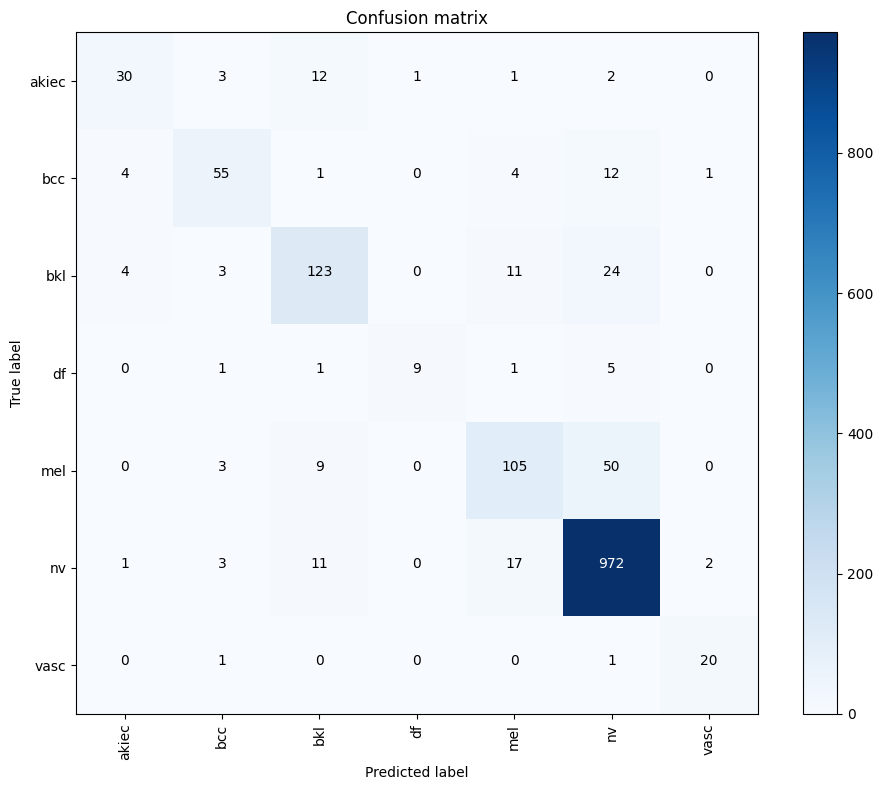

In [2]:
# ================================================================
# Evaluation - Safe Version
# ================================================================
def get_preds_safe(generator):
    """Collect predictions from generator safely"""
    preds, labels = [], []
    n_batches = len(generator)
    
    for i in range(n_batches):
        try:
            X, y = generator[i]
            if isinstance(X, tuple):
                p = model.predict(X, verbose=0)
            else:
                p = model.predict(X, verbose=0)
            preds.append(p)
            labels.append(y)
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not preds:
        return np.array([]), np.array([])
    
    return np.vstack(preds), np.vstack(labels)

preds, true = get_preds_safe(test_gen)
pred_labels = np.argmax(preds, axis=1)
true_labels = np.argmax(true, axis=1)

acc = accuracy_score(true_labels, pred_labels)
print(f"Test Accuracy: {acc*100:.2f}%")
print("Classification Report:\n", classification_report(true_labels, pred_labels, target_names=le.classes_, digits=4))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10,8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
plt.xticks(np.arange(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(np.arange(len(le.classes_)), le.classes_)
thresh = cm.max() / 2
for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j,i,cm[i,j], ha="center", color="white" if cm[i,j]>thresh else "black")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

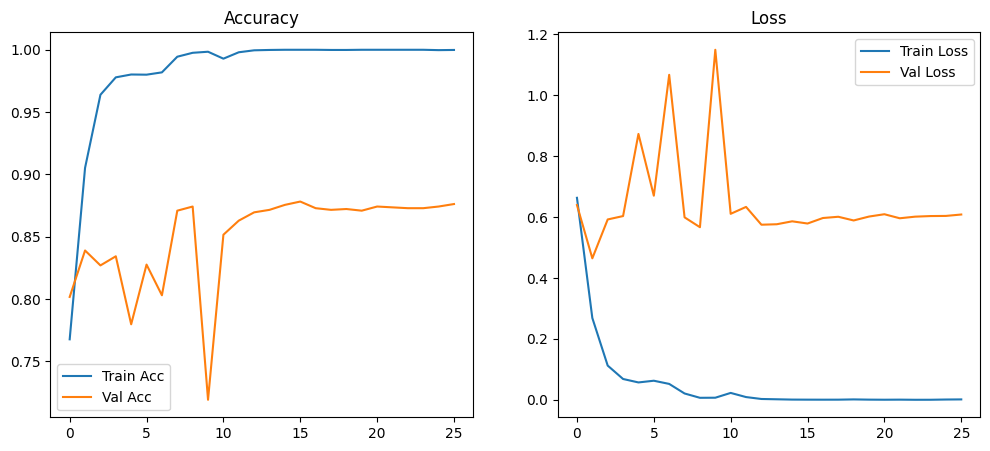

In [3]:
# ================================================================
# Training curves
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()
plt.show()

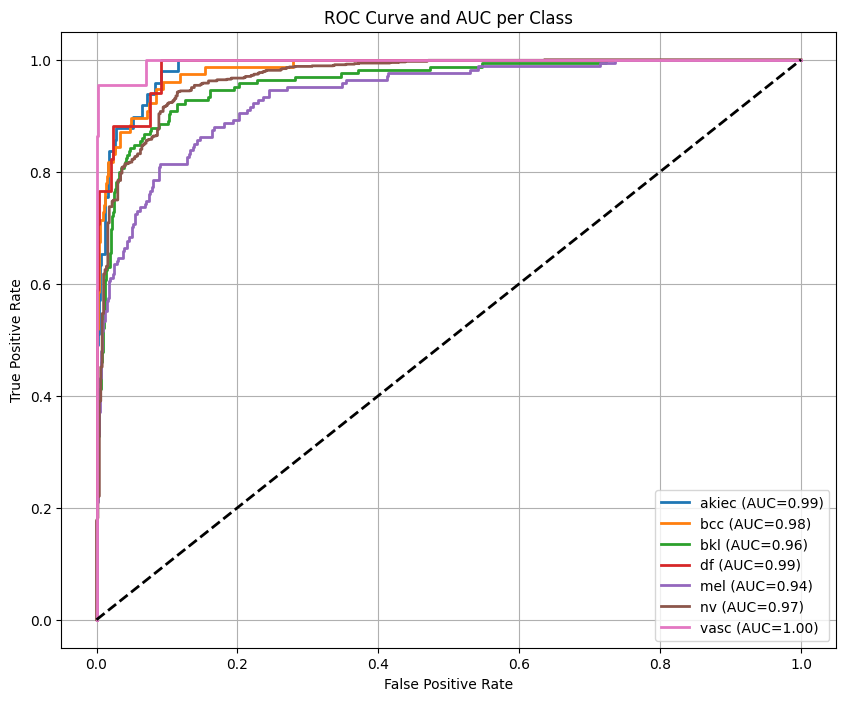

AUC for akiec: 0.9857
AUC for bcc: 0.9826
AUC for bkl: 0.9608
AUC for df: 0.9872
AUC for mel: 0.9361
AUC for nv: 0.9688
AUC for vasc: 0.9965
weighted-average AUC: 0.9862


In [4]:
# ================================================================
# ROC Curves - Safe Version
# ================================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def collect_predictions_for_roc(generator, model, num_batches=None):
    """Collect predictions from generator safely for ROC"""
    y_true_list = []
    y_pred_list = []
    
    n_batches = len(generator)
    if num_batches is not None:
        n_batches = min(n_batches, n_batches)
    
    if n_batches == 0:
        print(" Warning: Generator has no batches!")
        return np.array([]), np.array([])
    
    for i in range(n_batches):
        try:
            batch_x, batch_y = generator[i]
            
            if isinstance(batch_x, tuple):
                batch_pred = model.predict(batch_x, verbose=0)
            else:
                batch_pred = model.predict(batch_x, verbose=0)
            
            y_true_list.append(batch_y)
            y_pred_list.append(batch_pred)
            
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not y_true_list:
        print(" No predictions collected!")
        return np.array([]), np.array([])
    
    return np.concatenate(y_true_list, axis=0), np.concatenate(y_pred_list, axis=0)

y_true, y_pred = collect_predictions_for_roc(test_gen, model)

if y_true.size == 0 or y_pred.size == 0:
    print(" Failed to collect predictions, skipping ROC Curves")
else:
    if y_true.ndim == 2:
        y_true_indices = np.argmax(y_true, axis=1)
    else:
        y_true_indices = y_true

    n_classes = y_pred.shape[1]
    class_names = le.classes_

    y_true_bin = label_binarize(y_true_indices, classes=range(n_classes))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["weighted"], tpr["weighted"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["weighted"] = auc(fpr["weighted"], tpr["weighted"])

    plt.figure(figsize=(10, 8))
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"{class_names[i]} (AUC={roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve and AUC per Class")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    for i in range(n_classes):
        print(f"AUC for {class_names[i]}: {roc_auc[i]:.4f}")
    print(f"weighted-average AUC: {roc_auc['weighted']:.4f}")

In [5]:
# ================================================================
# Complete Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

precision = precision_score(true_labels, pred_labels, average="weighted")
sensitivity = recall_score(true_labels, pred_labels, average="weighted")
f1 = f1_score(true_labels, pred_labels, average="weighted")

cm = confusion_matrix(true_labels, pred_labels)
TN = []
FP = []
for i in range(len(cm)):
    tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    fp = np.sum(cm[:, i]) - cm[i, i]
    TN.append(tn)
    FP.append(fp)
specificity = np.mean(np.array(TN) / (np.array(TN) + np.array(FP)))

auc_score = roc_auc_score(true_labels, preds, multi_class="ovr", average="weighted")

print("="*50)
print(" COMPLETE METRICS SUMMARY")
print("="*50)
print(f" Accuracy    : {acc*100:.2f}%")
print(f" Specificity : {specificity*100:.2f}%")
print(f" Precision   : {precision*100:.2f}%")
print(f" Sensitivity : {sensitivity*100:.2f}%")
print(f" F1 Score    : {f1*100:.2f}%")
print("="*50)

 COMPLETE METRICS SUMMARY
 Accuracy    : 87.43%
 Specificity : 96.30%
 Precision   : 86.91%
 Sensitivity : 87.43%
 F1 Score    : 86.95%
